# 03 · OSM commercial features

Признаки окружения кандидатных точек из OpenStreetMap для CoffeeSpot AI. Работаем с той же сеткой из 2822 точек Алматы (EPSG:32643), что и в `02_candidate_locations.ipynb`.

| признак | что считаем | объекты OSM |
|---|---|---|
| `shops_500m` | магазины в радиусе 500 м | `shop=*`, кроме ТРЦ, пустующих и автомобильных |
| `malls_1000m` | торговые центры в радиусе 1000 м | `shop=mall` |
| `restaurants_500m` | рестораны в радиусе 500 м | `amenity=restaurant` |
| `metro_dist` | расстояние до ближайшей станции метро, м | `railway=station` + `station=subway` |
| `transit_stops_500m` | остановки общественного транспорта в радиусе 500 м | автобус/троллейбус, метро, ж/д |
| `parking_500m` | парковки в радиусе 500 м | `amenity=parking`, кроме частных |
| `major_roads_distance` | расстояние до ближайшей крупной дороги, м | `highway=motorway/trunk/primary/secondary` |
| `attractions_1000m` | достопримечательности в радиусе 1000 м | отобранные `tourism=*` и `historic=*` |

Для каждого признака одинаковый порядок: **извлечь объекты → проверить геометрии и дубликаты → посчитать значения для кандидатов → `describe()` и пропуски → карта → сохранить `candidate_id` + признак** в `data/processed/features/<признак>.csv`.

**Ключевые решения**
- **Источник — выгрузка Geofabrik `kazakhstan-latest.osm.pbf`, а не Overpass API.** Публичные Overpass-серверы регулярно отвечают «at capacity», а файл фиксирует снимок данных: у всех в команде получатся одинаковые значения. Файл лежит в `data/raw/` (уже в `.gitignore`).
- **Объекты берём в границе Алматы плюс 2 км.** Иначе у точек на краю города буферы 500/1000 м и расстояния до метро/дорог обрезались бы границей (краевой эффект).
- **`candidate_id` = номер строки в `candidate_locations.gpkg` (0…2821)**, порядок тот же, что в `02_candidate_locations.ipynb`. В общий файл дополнительно пишем `x`, `y`, чтобы проверить совпадение точек при объединении.
- **«В радиусе R» считаем так же, как `count_nearby_cafes`** из `src/spatial_features.py`: буфер R вокруг кандидата + `intersects`. Только векторно через `sjoin`, без цикла по точкам.

In [1]:
import hashlib
import re
import time
import urllib.request
from itertools import product
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
import pyogrio
import shapely
from matplotlib.colors import ListedColormap, PowerNorm
from shapely.geometry import Point

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
DATA_DIR = PROJECT_ROOT / "data" / "processed"
FEATURES_DIR = DATA_DIR / "features"
for folder in (RAW_DIR, DATA_DIR, FEATURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

PLACE = "Almaty, Kazakhstan"
CRS_METRIC = "EPSG:32643"
N_CANDIDATES = 2822
GRID_STEP_M = 500
STUDY_BUFFER_M = 2000  # насколько за границу города берём объекты OSM

ox.settings.cache_folder = str(PROJECT_ROOT / "cache")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

print("project root:", PROJECT_ROOT)
print("osmnx", ox.__version__, "| geopandas", gpd.__version__, "| pandas", pd.__version__,
      "| GDAL", pyogrio.__gdal_version_string__)

project root: C:\Users\user\Desktop\cafe-ai-loc\business-location-ai
osmnx 2.1.1 | geopandas 1.2.0 | pandas 3.1.1 | GDAL 3.12.4


## 0. Кандидатные точки

Если `data/processed/candidate_locations.gpkg` уже есть (его пишет `02_candidate_locations.ipynb`), берём точки оттуда. Если нет (папка `data/` не хранится в git), пересобираем сетку тем же алгоритмом, что в 02: шаг 500 м по bbox города, оставляем точки внутри границы. Проверка на 2822 точки гарантирует, что сетка совпала.

In [2]:
almaty = ox.geocode_to_gdf(PLACE)
almaty_m = almaty.to_crs(CRS_METRIC)
city_geometry = almaty_m.geometry.iloc[0]

candidates_path = DATA_DIR / "candidate_locations.gpkg"
if candidates_path.exists():
    candidates = gpd.read_file(candidates_path).to_crs(CRS_METRIC)
    print("загружено:", candidates_path.relative_to(PROJECT_ROOT))
else:
    min_x, min_y, max_x, max_y = almaty_m.total_bounds
    xs = np.arange(min_x, max_x, GRID_STEP_M)
    ys = np.arange(min_y, max_y, GRID_STEP_M)
    grid = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in product(xs, ys)], crs=CRS_METRIC)
    candidates = grid[grid.geometry.within(city_geometry)]
    print("candidate_locations.gpkg не найден, сетка пересобрана как в 02_candidate_locations.ipynb")

if "candidate_id" not in candidates.columns:
    candidates = candidates.reset_index(drop=True)
    candidates.insert(0, "candidate_id", np.arange(len(candidates)))
candidates = candidates[["candidate_id", "geometry"]].copy()
candidates["x"] = candidates.geometry.x.round(2)
candidates["y"] = candidates.geometry.y.round(2)

assert len(candidates) == N_CANDIDATES, f"ожидали {N_CANDIDATES} точек, получили {len(candidates)}"
assert candidates["candidate_id"].is_unique
assert candidates.crs.to_epsg() == 32643

study_area = city_geometry.buffer(STUDY_BUFFER_M)
study_bbox_wgs84 = tuple(gpd.GeoSeries([study_area], crs=CRS_METRIC).to_crs(4326).total_bounds)

print(candidates.shape, candidates.crs)
print(f"площадь города: {city_geometry.area / 1e6:.0f} км², зона поиска объектов (+{STUDY_BUFFER_M} м): {study_area.area / 1e6:.0f} км²")
candidates.head()

candidate_locations.gpkg не найден, сетка пересобрана как в 02_candidate_locations.ipynb
(2822, 4) EPSG:32643
площадь города: 704 км², зона поиска объектов (+2000 м): 1093 км²


,candidate_id,geometry,x,y
0,0,POINT (641765.589 4796397.813),641765.59,4796397.81
1,1,POINT (641765.589 4796897.813),641765.59,4796897.81
2,2,POINT (641765.589 4797397.813),641765.59,4797397.81
3,3,POINT (642265.589 4795897.813),642265.59,4795897.81
4,4,POINT (642265.589 4796397.813),642265.59,4796397.81


## 1. Данные OSM

1. `kazakhstan-latest.osm.pbf` (~230 МБ) скачивается с Geofabrik один раз, проверяется md5.
2. Из него один раз вырезаются объекты в bbox зоны поиска и сохраняются в `data/raw/almaty_osm_extract.gpkg` (три слоя GDAL: `points`, `lines`, `multipolygons`). Это ~1,5 минуты. Чтобы обновить данные, удалите оба файла.
3. GDAL кладёт часть тегов в отдельные колонки, а остальные в строку `other_tags` вида `"key"=>"value",...` (такой же формат, как у `almaty_office_points.gpkg` в 02). Разбираем её и оставляем нужные ключи колонками.

In [3]:
PBF_URL = "https://download.geofabrik.de/asia/kazakhstan-latest.osm.pbf"
PBF_PATH = RAW_DIR / "kazakhstan-latest.osm.pbf"
EXTRACT_PATH = RAW_DIR / "almaty_osm_extract.gpkg"
OSM_LAYERS = ["points", "lines", "multipolygons"]


def md5sum(path, chunk_size=2**20):
    digest = hashlib.md5()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(chunk_size), b""):
            digest.update(block)
    return digest.hexdigest()


if not PBF_PATH.exists():
    print("скачиваю", PBF_URL)
    urllib.request.urlretrieve(PBF_URL, PBF_PATH)
    expected_md5 = urllib.request.urlopen(PBF_URL + ".md5").read().decode().split()[0]
    if md5sum(PBF_PATH) != expected_md5:
        PBF_PATH.unlink()
        raise RuntimeError("md5 не совпал, файл удалён — запустите ячейку ещё раз")

pbf_date = pd.Timestamp(PBF_PATH.stat().st_mtime, unit="s")
print(f"{PBF_PATH.name}: {PBF_PATH.stat().st_size / 1e6:.0f} МБ, скачан {pbf_date:%Y-%m-%d}, md5 {md5sum(PBF_PATH)}")

if not EXTRACT_PATH.exists():
    for layer in OSM_LAYERS:
        start = time.time()
        part = pyogrio.read_dataframe(PBF_PATH, layer=layer, bbox=study_bbox_wgs84)
        part.to_file(EXTRACT_PATH, layer=layer, driver="GPKG")
        print(f"  {layer}: {len(part)} объектов, {time.time() - start:.0f} с")
print(pyogrio.list_layers(EXTRACT_PATH))

kazakhstan-latest.osm.pbf: 226 МБ, скачан 2026-11-15, md5 ccf644be8797ed30f0f6a21b3b01d59d
[['points' 'Point']
 ['lines' 'LineString']
 ['multipolygons' 'MultiPolygon']]


In [4]:
# ключи OSM, которые нужны для восьми признаков
TAG_KEYS = [
    "name", "name:ru", "name:kk", "name:en",
    "shop", "amenity", "building",
    "highway", "railway", "public_transport", "station", "subway", "construction", "tunnel",
    "parking", "access",
    "tourism", "historic", "memorial",
]
OTHER_TAGS_RE = re.compile(r'"((?:[^"\\]|\\.)*)"=>"((?:[^"\\]|\\.)*)"')


def parse_other_tags(value):
    return dict(OTHER_TAGS_RE.findall(value)) if isinstance(value, str) else {}


def read_osm_layer(layer):
    raw = gpd.read_file(EXTRACT_PATH, layer=layer)
    if layer == "multipolygons":
        # замкнутые линии приходят с osm_way_id, мультиполигоны-отношения с osm_id
        osm_type = np.where(raw["osm_way_id"].notna(), "way", "relation")
        osm_id = raw["osm_way_id"].fillna(raw["osm_id"])
    else:
        osm_type = "node" if layer == "points" else "way"
        osm_id = raw["osm_id"]
    other = raw["other_tags"].map(parse_other_tags)
    out = gpd.GeoDataFrame(
        {"osm_type": osm_type, "osm_id": osm_id.astype("int64")},
        geometry=raw.geometry, crs=raw.crs, index=raw.index,
    )
    for key in TAG_KEYS:
        from_other = other.map(lambda tags: tags.get(key))
        out[key] = raw[key].where(raw[key].notna(), from_other) if key in raw.columns else from_other
    return out


start = time.time()
osm = pd.concat([read_osm_layer(layer) for layer in OSM_LAYERS], ignore_index=True)
osm = gpd.GeoDataFrame(osm, geometry="geometry", crs="EPSG:4326").to_crs(CRS_METRIC)
osm = osm[osm.intersects(study_area)].reset_index(drop=True)

print(f"объектов OSM в зоне поиска: {len(osm)} ({time.time() - start:.0f} с)")
print("типы геометрий:", osm.geom_type.value_counts().to_dict())
print("пустых геометрий:", int(osm.geometry.is_empty.sum()), "| невалидных:", int((~osm.geometry.is_valid).sum()),
      "| дублей osm_type+osm_id:", int(osm.duplicated(["osm_type", "osm_id"]).sum()))

объектов OSM в зоне поиска: 393573 (15 с)
типы геометрий: {'MultiPolygon': 261071, 'LineString': 85587, 'Point': 46915}


пустых геометрий: 0 | невалидных: 79 | дублей osm_type+osm_id: 0


## 2. Общие функции

- `check_geometries` — отчёт о пустых/невалидных геометриях, дублях OSM-id и совпадающих геометриях; невалидные чинит `make_valid`.
- `drop_duplicate_objects` — склеивает объекты, которые описывают одно место. Типичный случай в OSM: заведение нанесено и точкой, и полигоном здания, или точка задвоена. Правило подбирается под слой (см. docstring). Из группы дублей остаётся полигон, если он есть.
- `count_within` — число объектов в буфере R вокруг каждого кандидата; `nearest_distance` — расстояние до ближайшего объекта.
- `describe_feature`, `plot_feature`, `save_feature` — описательная статистика, гистограмма + карта, сохранение `candidate_id` + признак.

In [5]:
NAME_COLS = ["name", "name:ru", "name:kk", "name:en"]


def check_geometries(gdf, label):
    gdf = gdf.copy()
    report = pd.Series({
        "объектов": len(gdf),
        "пустых геометрий": int((gdf.geometry.isna() | gdf.geometry.is_empty).sum()),
        "невалидных геометрий": int((~gdf.geometry.is_valid).sum()),
        "дублей osm_type+osm_id": int(gdf.duplicated(["osm_type", "osm_id"]).sum()),
        "одинаковая геометрия у разных объектов": int(gdf.geometry.to_wkb().duplicated().sum()),
    }, name=label)
    print(report.to_string())
    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty]
    invalid = ~gdf.geometry.is_valid
    if invalid.any():
        gdf.loc[invalid, "geometry"] = gdf.loc[invalid, "geometry"].make_valid()
    gdf = gdf.drop_duplicates(["osm_type", "osm_id"])
    print("типы геометрий:", gdf.geom_type.value_counts().to_dict())
    return gdf


def name_variants(row):
    names = set()
    for col in NAME_COLS:
        value = row[col]
        if isinstance(value, str) and value.strip():
            names.add(re.sub(r"[\W_]+", " ", value.lower()).strip())
    return frozenset(names)


def drop_duplicate_objects(gdf, max_dist_m, unnamed_rule="never", category_col=None, barriers=None):
    '''
    Склеивает объекты, которые описывают одно и то же место.
    Пара считается дублем, если расстояние между геометриями <= max_dist_m и
      * совпадает хотя бы одно имя (name / name:ru / name:kk / name:en), или
      * unnamed_rule="contained": у одного из пары нет имени, категории совпадают и один объект лежит внутри другого
        (точка заведения внутри полигона того же заведения);
      * unnamed_rule="nearby": у одного из пары нет имени и категории совпадают.
    barriers: линии (например, оси дорог). Если отрезок между объектами пересекает такую линию,
    это разные объекты (остановки по разные стороны улицы), даже если имена совпадают.
    Группы строятся транзитивно (компоненты связности); из группы остаётся полигон, если он есть.
    '''
    g = gdf.reset_index(drop=True).copy()
    names = g.apply(name_variants, axis=1)
    has_name = (names.map(len) > 0).to_numpy()

    left, right = g.sindex.query(g.geometry, predicate="dwithin", distance=max_dist_m)
    upper = left < right
    left, right = left[upper], right[upper]

    same_name = np.array([bool(names.iat[i] & names.iat[j]) for i, j in zip(left, right)], dtype=bool)
    one_unnamed = ~(has_name[left] & has_name[right])
    if category_col is None:
        same_category = np.ones(len(left), dtype=bool)
    else:
        category = g[category_col].to_numpy(dtype=object)
        same_category = category[left] == category[right]
    geoms = np.asarray(g.geometry.array)
    if unnamed_rule == "contained":
        contained = shapely.covers(geoms[left], geoms[right]) | shapely.covers(geoms[right], geoms[left])
        unnamed_dup = one_unnamed & same_category & contained
    elif unnamed_rule == "nearby":
        unnamed_dup = one_unnamed & same_category
    else:
        unnamed_dup = np.zeros(len(left), dtype=bool)
    is_dup = same_name | unnamed_dup
    n_separated = 0
    if barriers is not None and len(left):
        ends = np.stack([shapely.get_coordinates(shapely.point_on_surface(geoms[left])),
                         shapely.get_coordinates(shapely.point_on_surface(geoms[right]))], axis=1)
        segment_idx, _ = barriers.sindex.query(shapely.linestrings(ends), predicate="crosses")
        separated = np.zeros(len(left), dtype=bool)
        separated[np.unique(segment_idx)] = True
        n_separated = int((is_dup & separated).sum())
        is_dup &= ~separated

    graph = nx.Graph()
    graph.add_nodes_from(range(len(g)))
    graph.add_edges_from(zip(left[is_dup], right[is_dup]))
    g["dup_group"] = -1
    for group_id, members in enumerate(nx.connected_components(graph)):
        g.loc[list(members), "dup_group"] = group_id

    is_area = g.geom_type.isin(["Polygon", "MultiPolygon"]).astype(int)
    priority = is_area * 100 + g[NAME_COLS].notna().sum(axis=1)
    kept = (g.assign(_priority=priority)
              .sort_values("_priority", ascending=False, kind="stable")
              .drop_duplicates("dup_group")
              .drop(columns="_priority")
              .sort_index()
              .reset_index(drop=True))

    pairs = pd.DataFrame({
        "name_1": g["name"].to_numpy(dtype=object)[left[is_dup]],
        "geom_1": g.geom_type.to_numpy()[left[is_dup]],
        "name_2": g["name"].to_numpy(dtype=object)[right[is_dup]],
        "geom_2": g.geom_type.to_numpy()[right[is_dup]],
        "dist_m": shapely.distance(geoms[left[is_dup]], geoms[right[is_dup]]).round(1),
    })
    n_groups = int((g["dup_group"].value_counts() > 1).sum())
    if barriers is not None:
        print(f"пар, разделённых дорогой (не дубли): {n_separated}")
    print(f"найдено пар-дублей: {len(pairs)}; удалено объектов: {len(g) - len(kept)} "
          f"(в {n_groups} группах); осталось: {len(kept)}")
    return kept, pairs


def count_within(objects, radius_m, feature_name, as_points=True):
    '''Число объектов в буфере radius_m вокруг каждого кандидата.
    as_points=True: объект берётся представительной точкой (как cafes_points в 01);
    as_points=False: считается по реальной геометрии (для крупных площадных объектов).'''
    objs = objects[["geometry"]].copy()
    if as_points:
        objs["geometry"] = objs.geometry.representative_point()
    buffers = candidates[["candidate_id", "geometry"]].copy()
    buffers["geometry"] = buffers.geometry.buffer(radius_m)
    hits = gpd.sjoin(buffers, objs, how="inner", predicate="intersects")
    counts = hits.groupby("candidate_id").size()
    result = candidates[["candidate_id"]].copy()
    result[feature_name] = result["candidate_id"].map(counts).fillna(0).astype(int)
    return result


def nearest_distance(objects, feature_name):
    '''Расстояние (м) от кандидата до ближайшего объекта (до края геометрии).'''
    joined = gpd.sjoin_nearest(
        candidates[["candidate_id", "geometry"]], objects[["geometry"]], how="left", distance_col=feature_name
    )
    joined = joined.drop_duplicates("candidate_id")  # при равных расстояниях sjoin_nearest дублирует строки
    result = candidates[["candidate_id"]].merge(joined[["candidate_id", feature_name]], on="candidate_id", how="left")
    result[feature_name] = result[feature_name].round(1)
    return result


def describe_feature(result, feature_name):
    assert len(result) == N_CANDIDATES and result["candidate_id"].is_unique
    values = result[feature_name]
    print(values.describe().round(2).to_string())
    print(f"пропусков: {values.isna().sum()} | нулей: {(values == 0).sum()} ({(values == 0).mean():.1%})")

In [6]:
# одноцветная последовательная шкала; светлый край обрезан, чтобы малые значения были видны на сером фоне
BLUES = ListedColormap(plt.cm.Blues(np.linspace(0.3, 1.0, 256)))
BLUES_R = ListedColormap(plt.cm.Blues(np.linspace(1.0, 0.2, 256)))
INK, MUTED, GRID = "#333333", "#888888", "#e6e6e6"


def plot_feature(result, feature_name, title, distance=False, overlay=None, overlay_style=None):
    data = candidates[["candidate_id", "geometry"]].merge(result, on="candidate_id")
    values = data[feature_name]
    fig, (ax_hist, ax_map) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1, 1.25]})

    if distance:
        hist_values, bins = values, 40
        hist_title, median_label = f"Распределение {feature_name}", "медиана"
    else:
        # у счётных признаков большинство точек = 0; без нулей виден хвост распределения
        hist_values = values[values > 0]
        top = int(hist_values.max()) if len(hist_values) else 1
        bins = np.arange(0.5, top + 1.5) if top <= 40 else 40
        hist_title = f"{feature_name} > 0: {len(hist_values)} точек (нулей {(values == 0).mean():.0%}, здесь не показаны)"
        median_label = "медиана среди > 0"
    ax_hist.hist(hist_values, bins=bins, color="#2f6db0", edgecolor="white", linewidth=0.6)
    ax_hist.set_title(hist_title, color=INK, loc="left")
    ax_hist.set_xlabel("метры" if distance else "объектов в радиусе", color=MUTED)
    ax_hist.set_ylabel("кандидатных точек", color=MUTED)
    ax_hist.grid(axis="y", color=GRID)
    ax_hist.set_axisbelow(True)
    for side in ("top", "right"):
        ax_hist.spines[side].set_visible(False)
    if len(hist_values):
        median = hist_values.median()
        ax_hist.axvline(median, color=INK, linewidth=1, linestyle="--")
        ax_hist.annotate(f"{median_label}: {median:,.0f}", xy=(median, 0.95), xycoords=("data", "axes fraction"),
                         xytext=(4, 0), textcoords="offset points", color=INK, fontsize=9)

    almaty_m.plot(ax=ax_map, color="#f3f3f3", edgecolor="#b5b5b5", linewidth=0.6)
    if distance:
        # корневая шкала: половина точек в пределах ~1 км, на линейной шкале они слились бы в один цвет
        norm = PowerNorm(gamma=0.5, vmin=0, vmax=values.max())
        data.plot(ax=ax_map, column=feature_name, cmap=BLUES_R, norm=norm, markersize=9, legend=True,
                  legend_kwds={"label": f"{feature_name}, м (темнее = ближе, шкала √)", "shrink": 0.7})
    else:
        data[values == 0].plot(ax=ax_map, color="#d6d6d6", markersize=5)
        positive = data[values > 0]
        vmax = max(1, positive[feature_name].quantile(0.99)) if len(positive) else 1
        positive.plot(ax=ax_map, column=feature_name, cmap=BLUES, vmin=1, vmax=vmax, markersize=9, legend=True,
                      legend_kwds={"label": f"{feature_name} (серые точки = 0; шкала до 99-го перцентиля)", "shrink": 0.7})
    if overlay is not None:
        overlay.plot(ax=ax_map, **(overlay_style or {}))
    ax_map.set_title(title, color=INK, loc="left")
    ax_map.set_axis_off()
    plt.tight_layout()
    plt.show()


def save_feature(result, feature_name):
    path = FEATURES_DIR / f"{feature_name}.csv"
    result[["candidate_id", feature_name]].to_csv(path, index=False)
    check = pd.read_csv(path)
    assert check.shape == (N_CANDIDATES, 2) and check[feature_name].notna().all()
    assert (check["candidate_id"] == candidates["candidate_id"]).all()
    print("сохранено:", path.relative_to(PROJECT_ROOT), check.shape)


FEATURES = {}  # имя признака -> DataFrame(candidate_id, признак)

## 3. `shops_500m` — магазины в радиусе 500 м

**Извлечение.** Все объекты с тегом `shop=*`. У некоторых значение составное (`books;video_games;…`), тип берём по первому значению.

Исключаем:
- `shop=mall`: торговые центры считаются отдельно в `malls_1000m`, а здание ТРЦ не является «магазином».
- пустующие помещения (`vacant`, `disused`, `no`);
- автомобильные точки (`car`, `car_repair`, `car_parts`, `tyres`, мото/грузовые, `fuel`). Это не пешеходная торговля, и они сгущаются в промзонах. С ними признак путал бы торговые улицы с авторынками. Чтобы вернуть их, достаточно убрать значения из `SHOP_EXCLUDE`.

In [7]:
shops_raw = osm[osm["shop"].notna()].copy()
shops_raw["shop_type"] = shops_raw["shop"].str.split(";").str[0].str.strip()
print("объектов shop=*:", len(shops_raw), "| разных значений shop:", shops_raw["shop_type"].nunique())
shops_raw["shop_type"].value_counts().head(25).to_frame().T

объектов shop=*: 4383 | разных значений shop: 132


shop_type,convenience,supermarket,clothes,car_repair,outpost,beauty,florist,hairdresser,electronics,car,confectionery,alcohol,pawnbroker,greengrocer,mobile_phone,mall,cosmetics,car_parts,shoes,e-cigarette,furniture,bakery,hardware,sports,optician
count,871,258,225,201,193,173,130,126,110,90,89,87,84,82,77,77,71,67,60,55,54,54,51,51,48


In [8]:
SHOP_EXCLUDE = {
    "mall",                                          # отдельный признак malls_1000m
    "vacant", "disused", "no",                       # пустующие помещения
    "car", "car_repair", "car_parts", "tyres",       # автомобильные
    "truck", "truck_repair", "motorcycle", "motorcycle_repair", "fuel",
}
excluded = shops_raw["shop_type"].isin(SHOP_EXCLUDE)
print("исключено:", int(excluded.sum()))
print(shops_raw.loc[excluded, "shop_type"].value_counts().to_string())
print()
shops = check_geometries(shops_raw[~excluded], "shops")

исключено: 483
shop_type
car_repair           201
car                   90
mall                  77
car_parts             67
tyres                 18
fuel                  18
motorcycle            10
motorcycle_repair      1
truck_repair           1

объектов                                  3900
пустых геометрий                             0
невалидных геометрий                         0
дублей osm_type+osm_id                       0
одинаковая геометрия у разных объектов       1
типы геометрий: {'Point': 3622, 'MultiPolygon': 278}


**Дубликаты.** Пересечение OSM-id и полностью одинаковые геометрии проверены выше. Остаются «смысловые» дубли: один магазин нанесён точкой внутри своего полигона или двумя точками рядом. Для магазинов склеиваем только пары с **одинаковым именем в пределах 30 м**. Правило «безымянная точка внутри полигона» здесь не подходит: в одном торговом здании много разных магазинов.

In [9]:
shops, shop_duplicates = drop_duplicate_objects(shops, max_dist_m=30, unnamed_rule="never")
shop_duplicates.sort_values("dist_m").head(15)

найдено пар-дублей: 17; удалено объектов: 17 (в 17 группах); осталось: 3883


,name_1,geom_1,name_2,geom_2,dist_m
0,Академкнига,Point,Академкнига,Point,0.0
1,Дана,Point,Дана,Point,0.0
6,Детский Мир,Point,Детский мир,MultiPolygon,0.0
4,MonAmie,Point,MonAmie,MultiPolygon,0.0
10,Magnum,Point,Магнум,MultiPolygon,0.0
12,Paul,Point,Paul,MultiPolygon,0.0
9,Toimart,Point,Toimart,MultiPolygon,0.0
16,Асем,MultiPolygon,Асем,MultiPolygon,0.0
13,Kerama Marazzi,Point,Kerama Marazzi,Point,3.0
2,Уют,Point,Уют,MultiPolygon,3.5


In [10]:
FEATURES["shops_500m"] = count_within(shops, 500, "shops_500m", as_points=True)
describe_feature(FEATURES["shops_500m"], "shops_500m")

count    2822.00
mean        4.11
std        12.00
min         0.00
25%         0.00
50%         0.00
75%         2.00
max       147.00
пропусков: 0 | нулей: 1807 (64.0%)


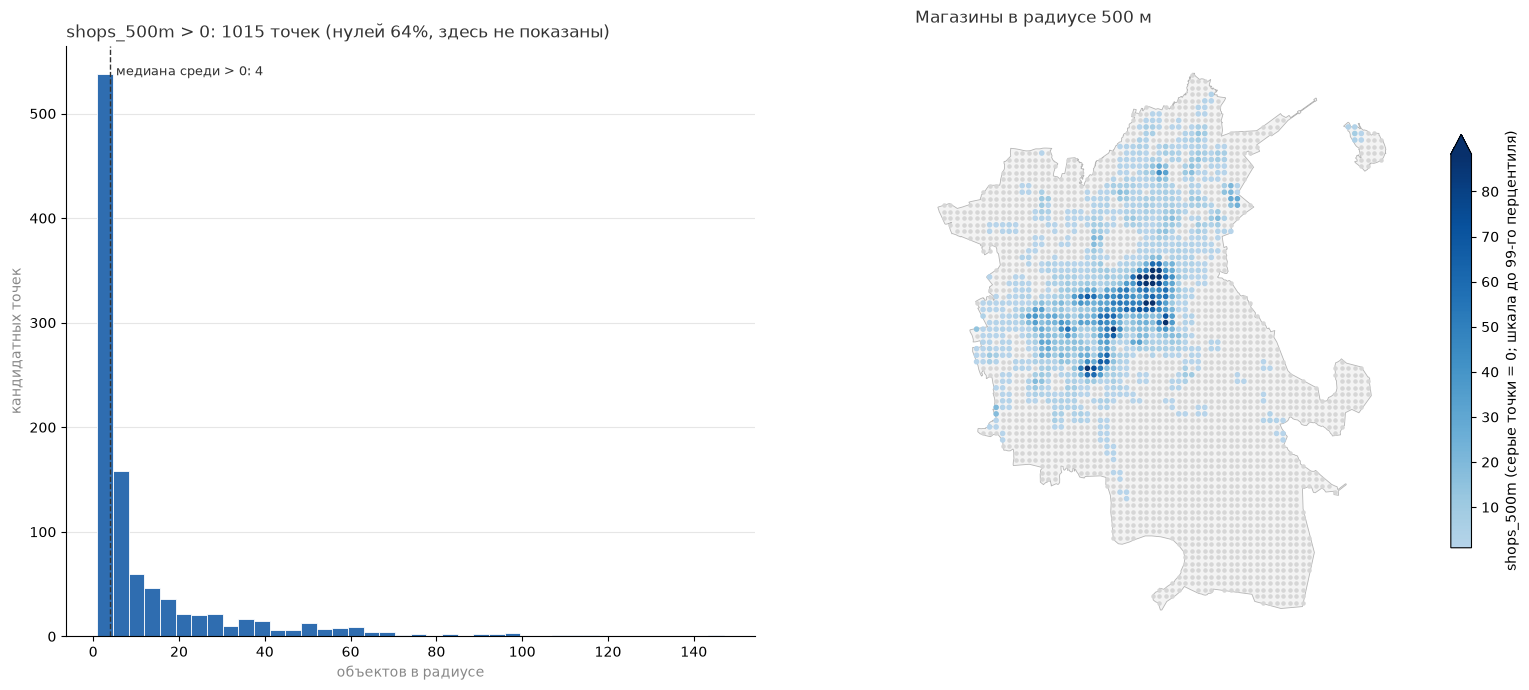

In [11]:
plot_feature(FEATURES["shops_500m"], "shops_500m", "Магазины в радиусе 500 м")

In [12]:
save_feature(FEATURES["shops_500m"], "shops_500m")

сохранено: data\processed\features\shops_500m.csv (2822, 2)


## 4. `malls_1000m` — торговые центры в радиусе 1000 м

**Извлечение.** `shop=mall`. Узлы с «ТЦ/ТРЦ» в имени, но без тега `shop` — это в основном остановки и входы, названные по торговому центру; их не берём.

**Дубликаты.** ТРЦ часто нанесён и точкой, и полигоном, а комплекс бывает разбит на несколько полигонов-павильонов. Склеиваем одинаковые имена в пределах 30 м и безымянную часть, лежащую внутри другого ТРЦ.

**Подсчёт** по реальной геометрии, а не по центру. Крупные ТРЦ занимают до 10 га (Апорт, MEGA), и попадание края здания в 1000 м — честный ответ на вопрос «есть ли ТРЦ рядом».

In [13]:
malls = check_geometries(osm[osm["shop"] == "mall"], "malls")
malls_area = malls.assign(area_m2=malls.geometry.area.round())
malls_area.sort_values("area_m2", ascending=False)[["osm_type", "name", "area_m2"]].head(10)

объектов                                  77
пустых геометрий                           0
невалидных геометрий                       0
дублей osm_type+osm_id                     0
одинаковая геометрия у разных объектов     0
типы геометрий: {'MultiPolygon': 68, 'Point': 9}


,osm_type,name,area_m2
132863,relation,Апорт Молл,95789.0
188878,way,Grand Park,78194.0
141242,way,MEGA Alma-Ata,54693.0
263511,way,Aport Mall East,50790.0
132779,relation,Dostyk Plaza,31058.0
290291,way,Алтын Орда,29024.0
196017,way,"""Forum Almaty"" Сауда, Ойын Орталығы",22042.0
205027,way,"ТРЦ ""MART Village""",21380.0
144562,way,"""Mega Park"" СОК",18818.0
141424,way,ADK,17652.0


In [14]:
malls, mall_duplicates = drop_duplicate_objects(malls, max_dist_m=30, unnamed_rule="contained")
mall_duplicates

найдено пар-дублей: 3; удалено объектов: 3 (в 3 группах); осталось: 74


,name_1,geom_1,name_2,geom_2,dist_m
0,Мерей,MultiPolygon,Мерей,MultiPolygon,0.0
1,Мерей 1-ші павильон,MultiPolygon,Мерей 1-ші павильон,MultiPolygon,0.0
2,Алтын Орда,MultiPolygon,Алтын Орда,MultiPolygon,16.9


count    2822.00
mean        0.34
std         1.14
min         0.00
25%         0.00
50%         0.00
75%         0.00
max        16.00
пропусков: 0 | нулей: 2380 (84.3%)


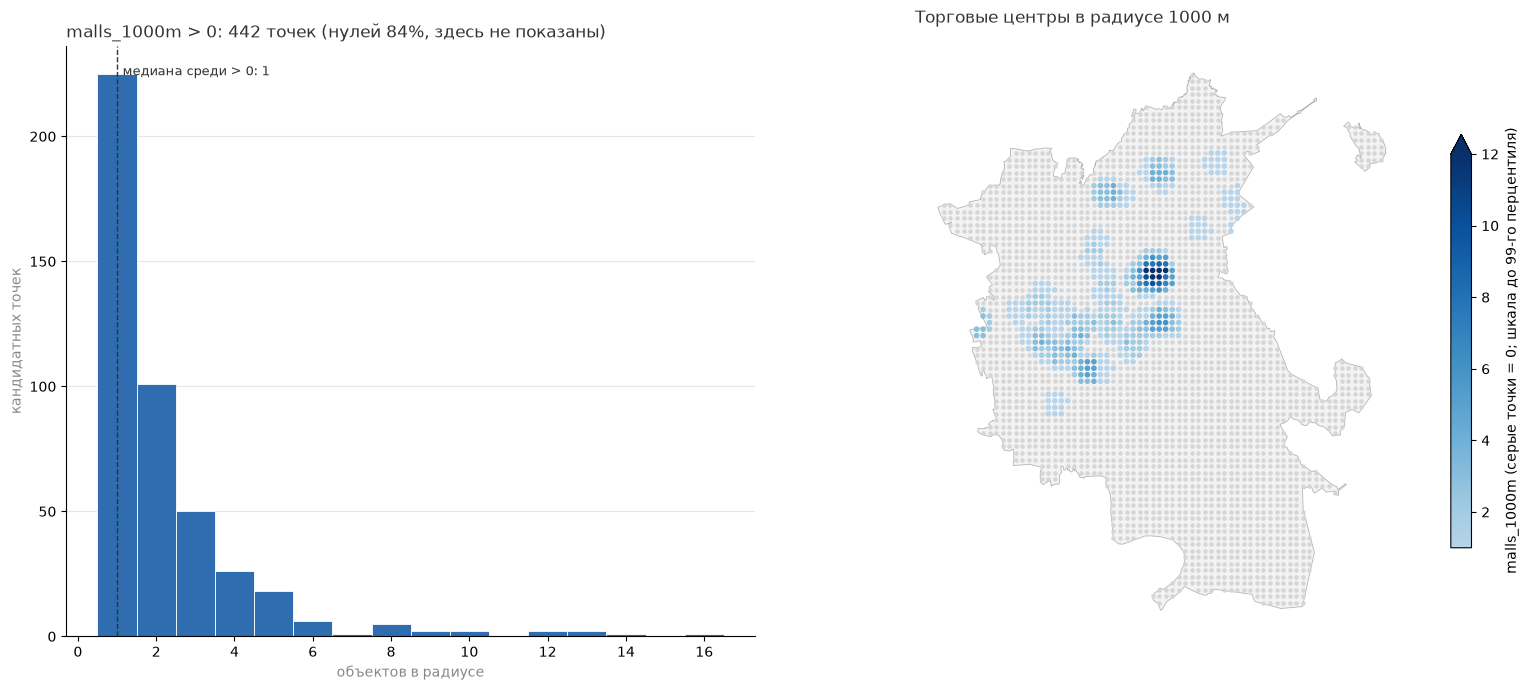

сохранено: data\processed\features\malls_1000m.csv (2822, 2)


In [15]:
FEATURES["malls_1000m"] = count_within(malls, 1000, "malls_1000m", as_points=False)
describe_feature(FEATURES["malls_1000m"], "malls_1000m")
plot_feature(FEATURES["malls_1000m"], "malls_1000m", "Торговые центры в радиусе 1000 м")
save_feature(FEATURES["malls_1000m"], "malls_1000m")

## 5. `restaurants_500m` — рестораны в радиусе 500 м

**Извлечение.** `amenity=restaurant`. Фастфуд (`fast_food`) и кафе в признак не входят: кафе — прямые конкуренты, и `cafes_*` уже посчитаны в 02.

**Дубликаты.** Одинаковое имя в пределах 30 м, плюс безымянная точка внутри полигона ресторана (то же заведение, нанесённое дважды).

In [16]:
print(osm.loc[osm["amenity"].isin(["restaurant", "fast_food", "food_court", "cafe"]), "amenity"].value_counts().to_string())
print()
restaurants = check_geometries(osm[osm["amenity"] == "restaurant"], "restaurants")
restaurants, restaurant_duplicates = drop_duplicate_objects(restaurants, max_dist_m=30, unnamed_rule="contained")
restaurant_duplicates.sort_values("dist_m").head(10)

amenity
cafe          753
restaurant    581
fast_food     449
food_court     11

объектов                                  581
пустых геометрий                            0
невалидных геометрий                        0
дублей osm_type+osm_id                      0
одинаковая геометрия у разных объектов      1
типы геометрий: {'Point': 461, 'MultiPolygon': 120}


найдено пар-дублей: 16; удалено объектов: 14 (в 12 группах); осталось: 567


,name_1,geom_1,name_2,geom_2,dist_m
0,NaN,Point,Достар,MultiPolygon,0.0
1,Жулдыз,Point,NaN,MultiPolygon,0.0
2,Konya Gunaydin,Point,Konya Gunaydin,MultiPolygon,0.0
3,Теплица,Point,NaN,MultiPolygon,0.0
4,Турандот,Point,Турандот,MultiPolygon,0.0
5,Tirol,Point,NaN,MultiPolygon,0.0
6,NaN,Point,NaN,MultiPolygon,0.0
7,Саудабай,Point,Саудабай,MultiPolygon,0.0
11,White Elephant,Point,NaN,MultiPolygon,0.0
10,Саудабай,Point,Саудабай,MultiPolygon,0.0


count    2822.00
mean        0.60
std         2.33
min         0.00
25%         0.00
50%         0.00
75%         0.00
max        33.00
пропусков: 0 | нулей: 2375 (84.2%)


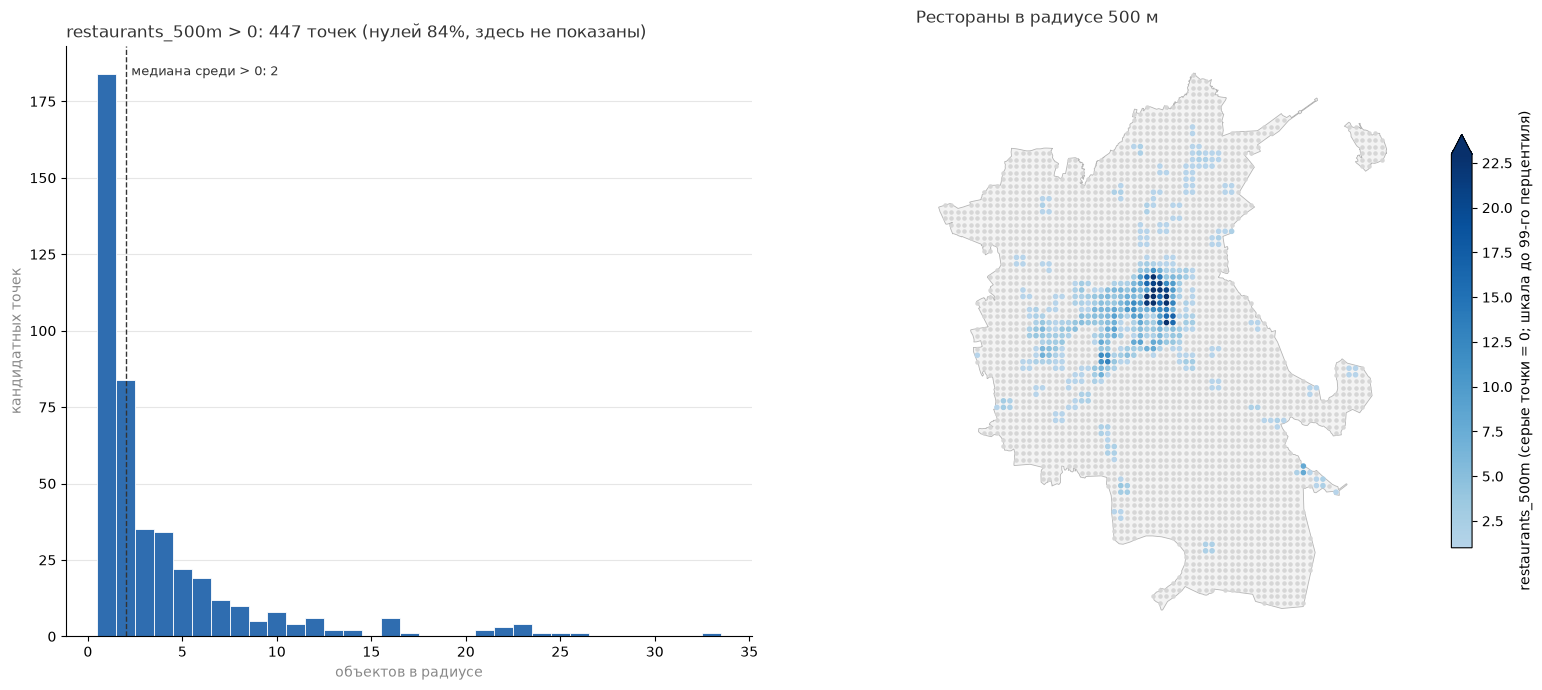

сохранено: data\processed\features\restaurants_500m.csv (2822, 2)


In [17]:
FEATURES["restaurants_500m"] = count_within(restaurants, 500, "restaurants_500m", as_points=True)
describe_feature(FEATURES["restaurants_500m"], "restaurants_500m")
plot_feature(FEATURES["restaurants_500m"], "restaurants_500m", "Рестораны в радиусе 500 м")
save_feature(FEATURES["restaurants_500m"], "restaurants_500m")

## 6. `metro_dist` — расстояние до ближайшей станции метро

**Извлечение.** Станция = узел `railway=station` + `station=subway`. Вместе с ней в OSM лежат `stop_position`, платформы, пути и входы; они описывают те же 11 станций, поэтому не берём их. Строящиеся станции (`construction=*`) исключаем.

**Дубликаты.** Одна станция = один объект: проверяем уникальность имени и склеиваем объекты станции в пределах 300 м.

**Пропусков быть не может:** у каждой точки есть ближайшая станция. Но метро в Алматы одна линия, поэтому у большинства точек расстояние будет километры. Для модели, вероятно, понадобится `log1p` или бинарный признак «метро ≤ 1 км» — это решим при сборке датасета.

In [18]:
under_construction = osm[(osm["subway"] == "yes") & osm["construction"].notna() & osm["name"].notna()]
print("строящиеся станции (не берём):", sorted(under_construction["name"].unique()))

metro = osm[(osm["railway"] == "station") & (osm["station"] == "subway") & osm["construction"].isna()]
metro = check_geometries(metro, "metro_stations")
metro, metro_duplicates = drop_duplicate_objects(metro, max_dist_m=300, unnamed_rule="nearby")
assert metro["name"].is_unique
metro[["osm_type", "osm_id", "name", "name:ru"]]

строящиеся станции (не берём): ['Қалқаман']
объектов                                  11
пустых геометрий                           0
невалидных геометрий                       0
дублей osm_type+osm_id                     0
одинаковая геометрия у разных объектов     0
типы геометрий: {'Point': 11}
найдено пар-дублей: 0; удалено объектов: 0 (в 0 группах); осталось: 11


,osm_type,osm_id,name,name:ru
0,node,2522351049,Абай,Абая
1,node,2522351050,Алатау,Алатау
2,node,2522351052,Байқоңыр,Байконур
3,node,2522351053,Жібек Жолы,Жибек Жолы
4,node,2522351055,Мұхтар Әуезов атындағы театры,Театр имени Мухтара Ауэзова
5,node,3464799078,Мәскеу,Москва
6,node,3464799079,Сайран,Сайран
7,node,9346636498,Райымбек батыр,Райымбек батыра
8,node,11496660771,Алмалы,Алмалы
9,node,13603952093,Бауыржан Момышұлы,Бауржан Момышулы


count     2822.00
mean      9027.62
std       5720.30
min         87.90
25%       4532.20
50%       8106.30
75%      12536.92
max      25253.50
пропусков: 0 | нулей: 0 (0.0%)
точек не дальше 500 м от метро: 36
точек не дальше 1000 м от метро: 105
точек не дальше 2000 м от метро: 249


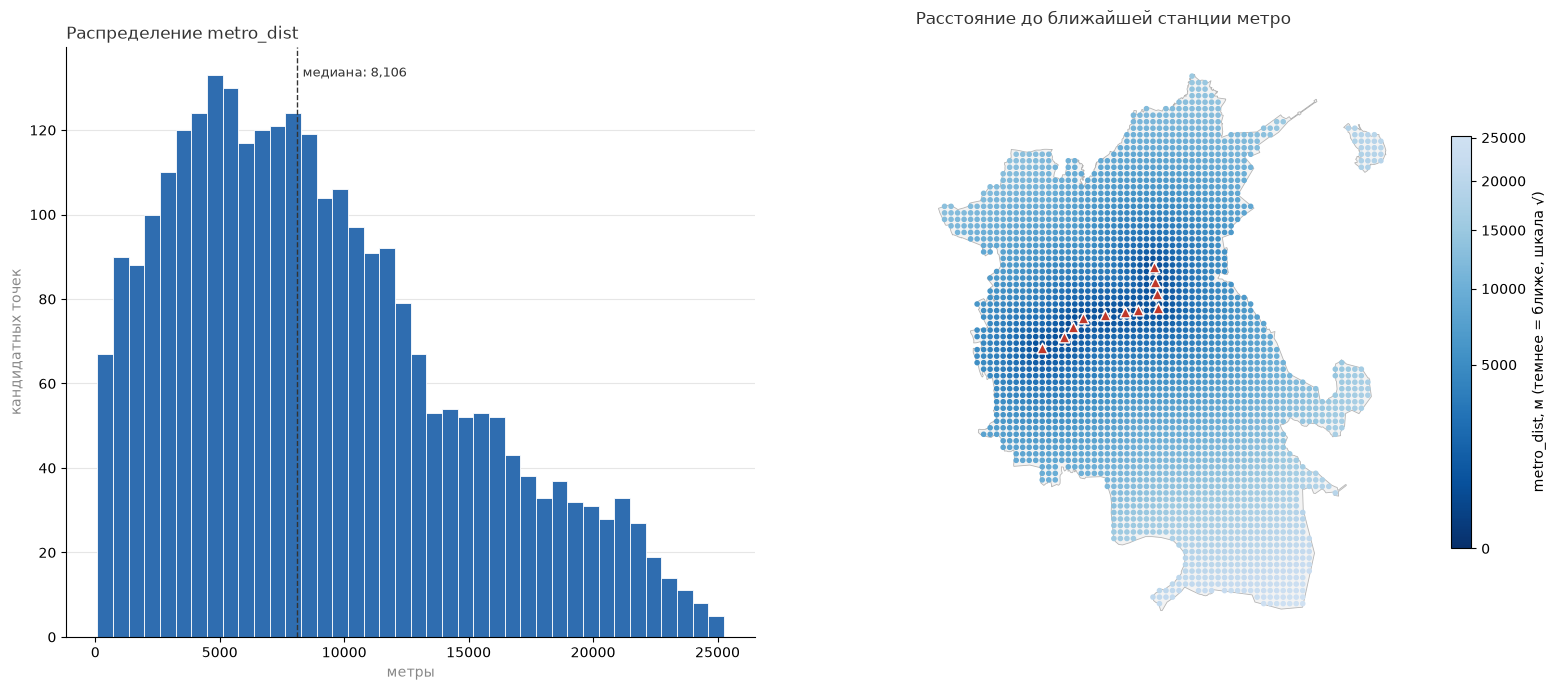

сохранено: data\processed\features\metro_dist.csv (2822, 2)


In [19]:
FEATURES["metro_dist"] = nearest_distance(metro, "metro_dist")
describe_feature(FEATURES["metro_dist"], "metro_dist")
for limit in (500, 1000, 2000):
    print(f"точек не дальше {limit} м от метро: {(FEATURES['metro_dist']['metro_dist'] <= limit).sum()}")
plot_feature(FEATURES["metro_dist"], "metro_dist", "Расстояние до ближайшей станции метро", distance=True,
             overlay=metro, overlay_style={"color": "#c0392b", "marker": "^", "markersize": 60, "edgecolor": "white"})
save_feature(FEATURES["metro_dist"], "metro_dist")

## 7. `transit_stops_500m` — остановки общественного транспорта в радиусе 500 м

В отличие от `bus_stops_500m` из 02 (только узлы `highway=bus_stop`), здесь все виды транспорта с поправкой на то, как в OSM рисуют остановки (PTv2):

| что | теги | как считаем |
|---|---|---|
| автобус/троллейбус, место ожидания | `highway=bus_stop` или `public_transport=platform` (не метро и не ж/д) | основной объект остановки |
| точка остановки на дороге | `public_transport=stop_position` | дубль платформы; берём, только если платформы нет ближе 30 м |
| метро | 11 станций из раздела 6 | одна станция = одна остановка |
| пригородная/ж/д станция | пассажирская `railway=station/halt`, не метро | склеиваем одноимённые в пределах 300 м |

**Дубликаты платформ.** Столб `highway=bus_stop` и полигон/линия платформы рядом — одна остановка. Склеиваем пары в пределах 10 м с совпадающим именем или если у одной нет имени, **но только если между ними нет проезжей части**. Остановки двух направлений носят одно имя и часто стоят в 5–10 м друг от друга через узкую улицу. Проверка показала, что у большинства одноимённых пар на 3–10 м между точками проходит ось дороги. Такие пары остаются двумя остановками, как и в `bus_stops_500m`.

**Ж/д станции** берём только пассажирские (`public_transport=station` или `railway=halt`). Например, «Медеу» на севере города — `railway=station` без пассажирских тегов.

In [20]:
CAR_ROADS = ["motorway", "trunk", "primary", "secondary", "tertiary", "unclassified", "residential", "living_street",
             "service", "motorway_link", "trunk_link", "primary_link", "secondary_link", "tertiary_link"]
road_axes = osm[osm["highway"].isin(CAR_ROADS) & (osm.geom_type == "LineString")]

is_metro_or_rail = osm["subway"].notna() | osm["railway"].notna()
platforms_raw = osm[(osm["highway"] == "bus_stop") | ((osm["public_transport"] == "platform") & ~is_metro_or_rail)]
stop_positions = osm[(osm["public_transport"] == "stop_position") & (osm["highway"] != "bus_stop") & ~is_metro_or_rail]
rail_raw = osm[
    osm["railway"].isin(["station", "halt"]) & (osm["station"] != "subway") & osm["construction"].isna()
    & ((osm["public_transport"] == "station") | (osm["railway"] == "halt"))
]

platforms = check_geometries(platforms_raw, "bus_trolleybus_platforms")
platforms, platform_duplicates = drop_duplicate_objects(platforms, max_dist_m=10, unnamed_rule="nearby", barriers=road_axes)
platform_duplicates.sort_values("dist_m", ascending=False).head(8)

объектов                                  2221
пустых геометрий                             0
невалидных геометрий                         0
дублей osm_type+osm_id                       0
одинаковая геометрия у разных объектов       0
типы геометрий: {'Point': 2160, 'MultiPolygon': 34, 'LineString': 27}


пар, разделённых дорогой (не дубли): 50
найдено пар-дублей: 89; удалено объектов: 83 (в 77 группах); осталось: 2138


,name_1,geom_1,name_2,geom_2,dist_m
17,NaN,Point,NaN,Point,9.9
61,Самал мейрамханасы,Point,Самал мейрамханасы,Point,9.7
2,Байзакова,Point,Байзакова,Point,9.3
56,Қарасай батыр,Point,NaN,LineString,8.9
15,Панфилова,Point,Панфилова,Point,8.5
14,Басенова,Point,NaN,Point,8.5
71,NaN,Point,NaN,Point,8.5
57,Улица Кулыбекова,Point,NaN,Point,8.4


In [21]:
has_platform_nearby = np.zeros(len(stop_positions), dtype=bool)
sp_idx, _ = platforms.sindex.query(stop_positions.geometry, predicate="dwithin", distance=30)
has_platform_nearby[np.unique(sp_idx)] = True
orphan_stop_positions = stop_positions[~has_platform_nearby]
print(f"stop_position: {len(stop_positions)}, из них с платформой ближе 30 м: {has_platform_nearby.sum()}, "
      f"без платформы (берём): {len(orphan_stop_positions)}")

rail = check_geometries(rail_raw, "rail_stations")
rail, rail_duplicates = drop_duplicate_objects(rail, max_dist_m=300, unnamed_rule="nearby")
print("ж/д станции:", sorted(rail["name"].dropna()))

transit_stops = pd.concat([
    platforms.assign(stop_kind="bus/trolleybus"),
    orphan_stop_positions.assign(stop_kind="bus/trolleybus (stop_position)"),
    metro.assign(stop_kind="metro"),
    rail.assign(stop_kind="rail"),
], ignore_index=True)
transit_stops = gpd.GeoDataFrame(transit_stops[["osm_type", "osm_id", "name", "stop_kind", "geometry"]],
                                 geometry="geometry", crs=CRS_METRIC)
transit_stops["stop_kind"].value_counts().to_frame()

stop_position: 865, из них с платформой ближе 30 м: 860, без платформы (берём): 5
объектов                                  9
пустых геометрий                          0
невалидных геометрий                      0
дублей osm_type+osm_id                    0
одинаковая геометрия у разных объектов    0
типы геометрий: {'Point': 7, 'MultiPolygon': 2}
найдено пар-дублей: 1; удалено объектов: 1 (в 1 группах); осталось: 8
ж/д станции: ['Алматы-1', 'Алматы-2', 'Баум тоғайы', 'Боралдай', 'Индустриальная', 'Көкөзек', 'Отыз', 'Әуеайлақ']


,count
stop_kind,
bus/trolleybus,2138
metro,11
rail,8
bus/trolleybus (stop_position),5


In [22]:
FEATURES["transit_stops_500m"] = count_within(transit_stops, 500, "transit_stops_500m", as_points=True)
describe_feature(FEATURES["transit_stops_500m"], "transit_stops_500m")

# сравнение с bus_stops_500m, посчитанным как в 02 (узлы highway=bus_stop внутри границы города, без дедупликации)
bus_stops_02 = osm[(osm["highway"] == "bus_stop") & osm.intersects(city_geometry)]
bus_stops_like_02 = count_within(bus_stops_02, 500, "bus_stops_500m_like_02")
pair = FEATURES["transit_stops_500m"].merge(bus_stops_like_02, on="candidate_id")
print("\nкорреляция с bus_stops_500m (как в 02): Pearson "
      f"{pair['transit_stops_500m'].corr(pair['bus_stops_500m_like_02']):.3f}, "
      f"Spearman {pair['transit_stops_500m'].corr(pair['bus_stops_500m_like_02'], method='spearman'):.3f}")

count    2822.00
mean        2.25
std         3.54
min         0.00
25%         0.00
50%         0.00
75%         4.00
max        25.00
пропусков: 0 | нулей: 1571 (55.7%)



корреляция с bus_stops_500m (как в 02): Pearson 0.991, Spearman 0.995


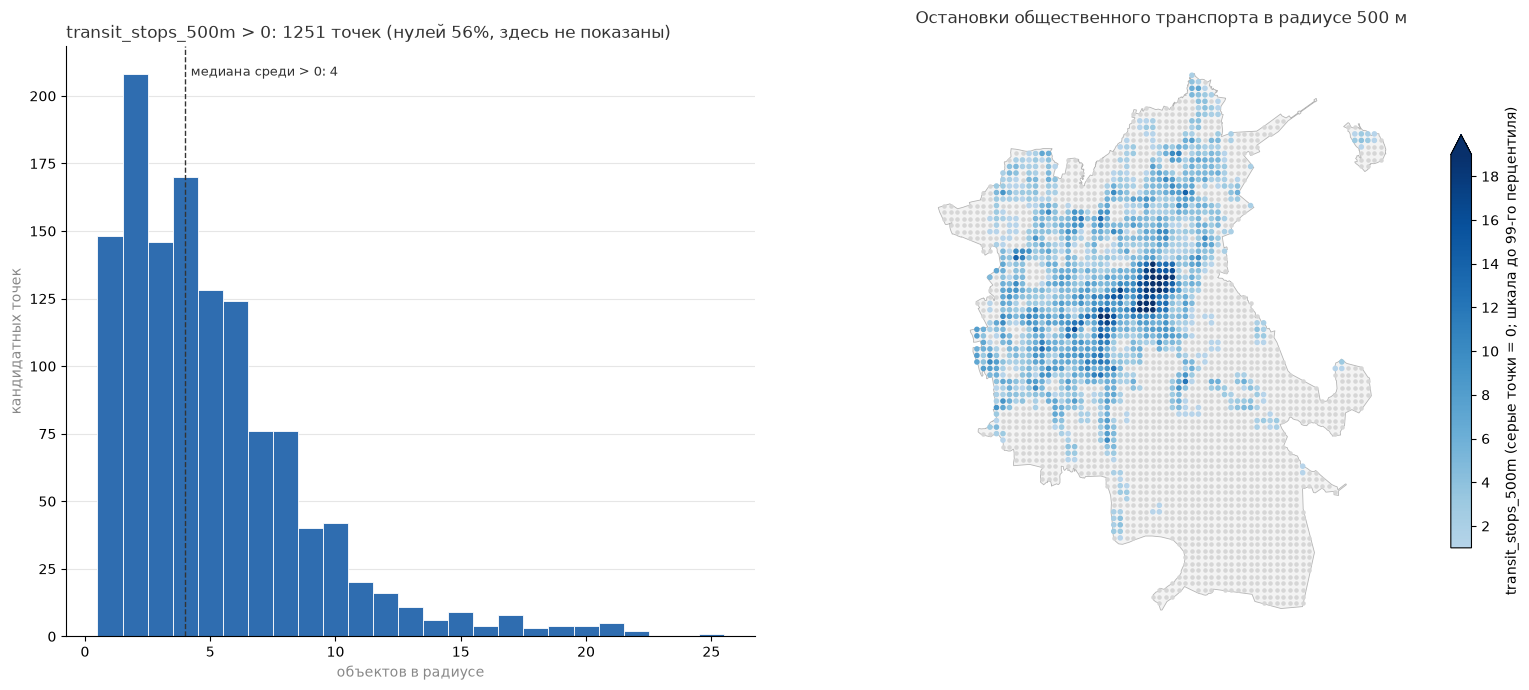

сохранено: data\processed\features\transit_stops_500m.csv (2822, 2)


In [23]:
plot_feature(FEATURES["transit_stops_500m"], "transit_stops_500m", "Остановки общественного транспорта в радиусе 500 м")
save_feature(FEATURES["transit_stops_500m"], "transit_stops_500m")

## 8. `parking_500m` — парковки в радиусе 500 м

**Извлечение.** `amenity=parking`. Не берём:
- `amenity=parking_entrance` (въезд в подземный паркинг, который уже есть полигоном) и `amenity=parking_space` (одно машиноместо);
- парковки, недоступные посетителю: `access=private/no/residents`;
- гаражные боксы и навесы во дворах (`parking=garage_boxes/carports`).

**Дубликаты.** Точка парковки внутри полигона парковки — одна парковка. Соседние полигоны с разными именами или без имени оставляем отдельными: в OSM это обычно разные площадки.

**Подсчёт** по геометрии: большая площадка, задевающая буфер 500 м, считается.

In [24]:
print(osm.loc[osm["amenity"].isin(["parking", "parking_entrance", "parking_space"]), "amenity"].value_counts().to_string())
parking_raw = osm[osm["amenity"] == "parking"]
print("\naccess:", parking_raw["access"].value_counts(dropna=False).to_dict())
print("parking:", parking_raw["parking"].value_counts(dropna=False).to_dict())

PARKING_EXCLUDE_ACCESS = {"private", "no", "residents"}
PARKING_EXCLUDE_TYPE = {"garage_boxes", "carports"}
excluded = parking_raw["access"].isin(PARKING_EXCLUDE_ACCESS) | parking_raw["parking"].isin(PARKING_EXCLUDE_TYPE)
print("исключено:", int(excluded.sum()))
print()
parking = check_geometries(parking_raw[~excluded], "parking")
parking, parking_duplicates = drop_duplicate_objects(parking, max_dist_m=5, unnamed_rule="contained")
print("площадь полигонов парковок, м²:",
      parking.loc[parking.geom_type != "Point"].geometry.area.describe().round().to_dict())

amenity
parking             2453
parking_entrance     122
parking_space         23

access: {nan: 2045, 'yes': 263, 'customers': 72, 'private': 48, 'permissive': 13, 'no': 6, 'permit': 4, 'residents': 2}
parking: {nan: 1747, 'surface': 541, 'street_side': 87, 'underground': 46, 'lane': 16, 'multi-storey': 8, 'carports': 2, 'garage': 1, 'garage_boxes': 1, 'rooftop': 1, 'shoulder': 1, 'half_on_kerb': 1, 'yes': 1}
исключено: 59

объектов                                  2394
пустых геометрий                             0
невалидных геометрий                         0
дублей osm_type+osm_id                       0
одинаковая геометрия у разных объектов       0
типы геометрий: {'MultiPolygon': 2151, 'Point': 243}


найдено пар-дублей: 10; удалено объектов: 10 (в 10 группах); осталось: 2384
площадь полигонов парковок, м²: {'count': 2148.0, 'mean': 1386.0, 'std': 3180.0, 'min': 15.0, '25%': 259.0, '50%': 568.0, '75%': 1322.0, 'max': 58393.0}


count    2822.00
mean        2.75
std         7.30
min         0.00
25%         0.00
50%         0.00
75%         2.00
max        84.00
пропусков: 0 | нулей: 1716 (60.8%)


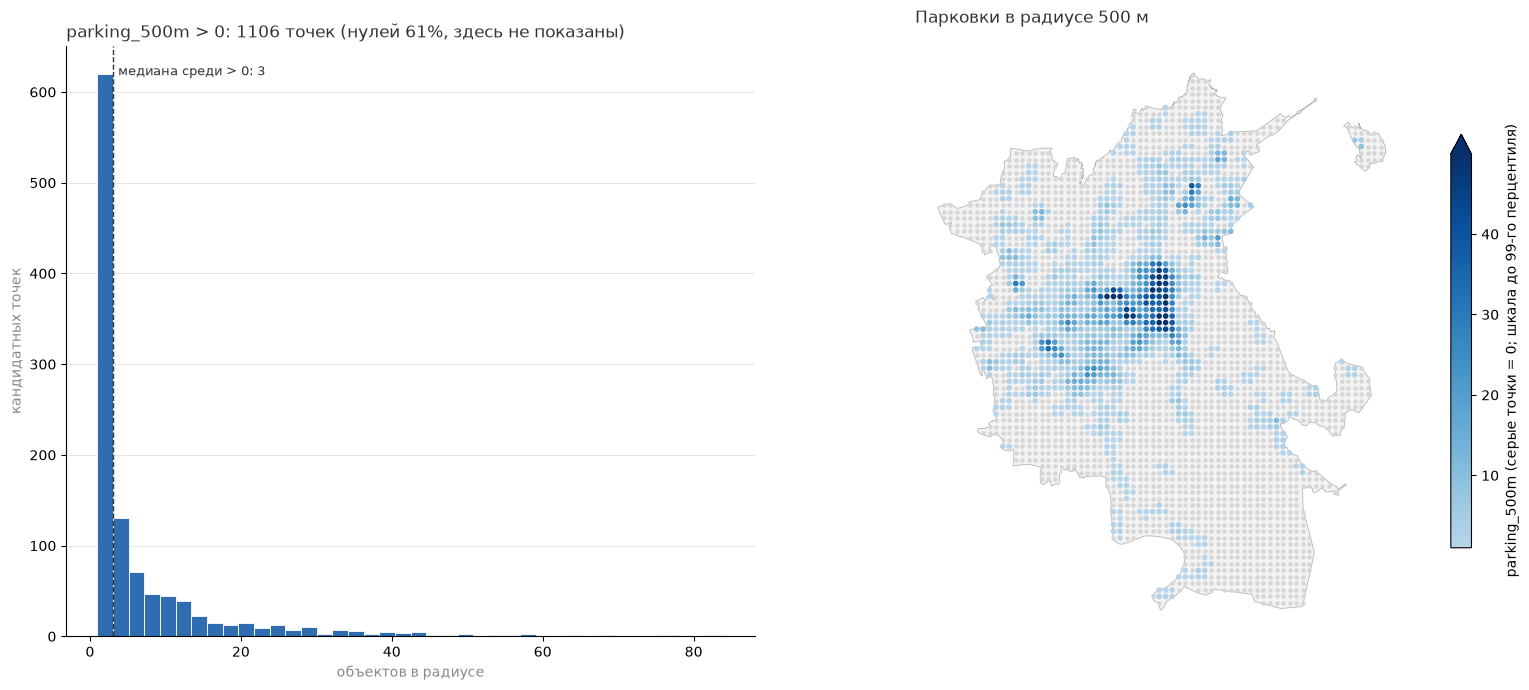

сохранено: data\processed\features\parking_500m.csv (2822, 2)


In [25]:
FEATURES["parking_500m"] = count_within(parking, 500, "parking_500m", as_points=False)
describe_feature(FEATURES["parking_500m"], "parking_500m")
plot_feature(FEATURES["parking_500m"], "parking_500m", "Парковки в радиусе 500 м")
save_feature(FEATURES["parking_500m"], "parking_500m")

## 9. `major_roads_distance` — расстояние до ближайшей крупной дороги

**Извлечение.** Линии `highway=motorway/trunk/primary/secondary` (магистрали, ВОАД, проспекты, крупные улицы). Съезды `*_link` и `tertiary` не берём: это уже не «крупная дорога».

**Тоннели исключаем.** Участок в тоннеле не виден с улицы и не даёт пешеходного потока, а расстояние до него было бы обманчиво маленьким.

**Дубликаты.** Для расстояния до ближайшей линии дубли сегментов не влияют на результат (минимум не меняется), поэтому только проверяем и показываем их число.

In [26]:
MAJOR_HIGHWAYS = ["motorway", "trunk", "primary", "secondary"]
roads_raw = osm[osm["highway"].isin(MAJOR_HIGHWAYS)]
print("геометрии:", roads_raw.geom_type.value_counts().to_dict())
roads_raw = roads_raw[roads_raw.geom_type.isin(["LineString", "MultiLineString"])]
in_tunnel = roads_raw["tunnel"].isin(["yes", "building_passage"])
print(f"сегментов в тоннеле (исключаем): {in_tunnel.sum()}, {roads_raw[in_tunnel].length.sum() / 1000:.1f} км")
roads = check_geometries(roads_raw[~in_tunnel], "major_roads")
(roads.assign(length_km=roads.length / 1000)
      .groupby("highway").agg(segments=("osm_id", "size"), length_km=("length_km", "sum"))
      .round(1).loc[MAJOR_HIGHWAYS])

геометрии: {'LineString': 3239}
сегментов в тоннеле (исключаем): 66, 3.2 км
объектов                                  3173
пустых геометрий                             0
невалидных геометрий                         0
дублей osm_type+osm_id                       0
одинаковая геометрия у разных объектов       0
типы геометрий: {'LineString': 3173}


,segments,length_km
highway,,
motorway,44,83.6
trunk,3,2.5
primary,1103,292.0
secondary,2023,423.8


count     2822.00
mean      2278.85
std       2861.80
min          0.30
25%        256.02
50%       1023.15
75%       3309.08
max      13975.80
пропусков: 0 | нулей: 0 (0.0%)
точек не дальше 100 м от крупной дороги: 309
точек не дальше 250 м от крупной дороги: 693
точек не дальше 500 м от крупной дороги: 1042


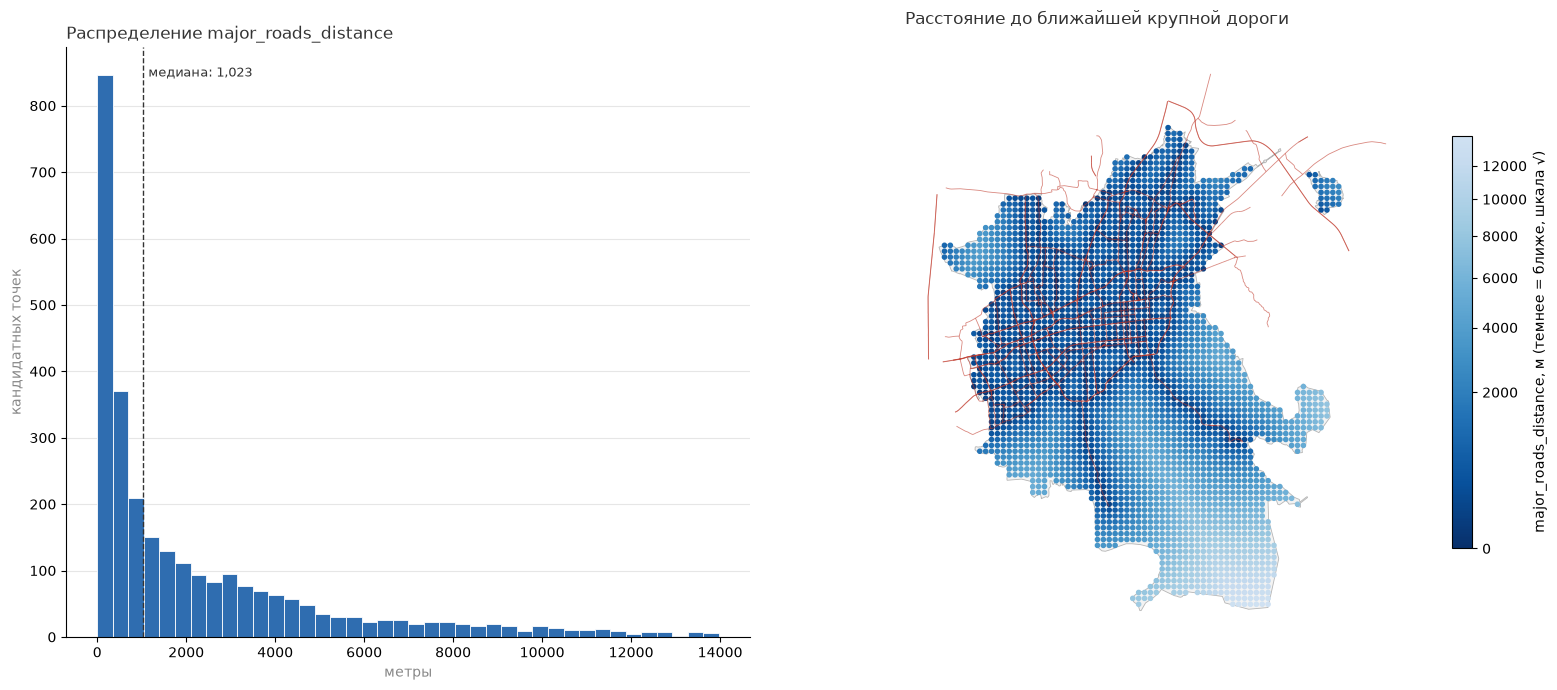

сохранено: data\processed\features\major_roads_distance.csv (2822, 2)


In [27]:
FEATURES["major_roads_distance"] = nearest_distance(roads, "major_roads_distance")
describe_feature(FEATURES["major_roads_distance"], "major_roads_distance")
for limit in (100, 250, 500):
    print(f"точек не дальше {limit} м от крупной дороги: {(FEATURES['major_roads_distance']['major_roads_distance'] <= limit).sum()}")
plot_feature(FEATURES["major_roads_distance"], "major_roads_distance", "Расстояние до ближайшей крупной дороги",
             distance=True, overlay=roads, overlay_style={"color": "#c0392b", "linewidth": 0.6, "alpha": 0.6})
save_feature(FEATURES["major_roads_distance"], "major_roads_distance")

## 10. `attractions_1000m` — достопримечательности в радиусе 1000 м

**Извлечение.** Только объекты, ради которых люди приходят:
- `tourism`: `attraction`, `museum`, `gallery`, `theme_park`, `zoo`, `aquarium`;
- `historic`: `monument`, `memorial`, `castle`, `ruins`, `archaeological_site`, `manor`, `fort`, `building`, `church`, `tomb`, `house`.

Не берём:
- мемориальные доски `memorial=plaque` (табличка на стене, не точка притяжения);
- `tourism=information` (стенды/указатели), `artwork` (сотни уличных скульптур и муралов, которые забили бы признак);
- `tourism=viewpoint`: ~100 точек, в основном на горных тропах в южной части города, это не городской пешеходный поток (видовые точки в черте города, как Кок-Тобе, обычно ещё и `tourism=attraction`);
- гостиницы, кемпинги и прочую инфраструктуру ночлега.

**Дубликаты.** Одинаковое имя в пределах 30 м, плюс безымянная часть внутри объекта той же категории. **Подсчёт** по геометрии: парки-аттракционы и зоопарк — большие полигоны.

In [28]:
ATTRACTION_TOURISM = {"attraction", "museum", "gallery", "theme_park", "zoo", "aquarium"}
ATTRACTION_HISTORIC = {"monument", "memorial", "castle", "ruins", "archaeological_site", "manor", "fort",
                       "building", "church", "tomb", "house"}
MEMORIAL_EXCLUDE = {"plaque", "blue_plaque"}

tourism_ok = osm["tourism"].isin(ATTRACTION_TOURISM)
historic_ok = osm["historic"].isin(ATTRACTION_HISTORIC) & ~osm["memorial"].isin(MEMORIAL_EXCLUDE)
attractions_raw = osm[tourism_ok | historic_ok].copy()
attractions_raw["attraction_type"] = attractions_raw["tourism"].where(
    attractions_raw["tourism"].isin(ATTRACTION_TOURISM), attractions_raw["historic"]
)
not_taken = osm[(osm["tourism"].notna() | osm["historic"].notna()) & ~(tourism_ok | historic_ok)]
not_taken_label = ("tourism=" + not_taken["tourism"]).fillna("historic=" + not_taken["historic"] + "/" + not_taken["memorial"].fillna("-"))
print("не взяли (топ):", not_taken_label.value_counts().head(8).to_dict())
print()
attractions = check_geometries(attractions_raw, "attractions")
attractions, attraction_duplicates = drop_duplicate_objects(
    attractions, max_dist_m=30, unnamed_rule="contained", category_col="attraction_type"
)
attractions["attraction_type"].value_counts().to_frame().T

не взяли (топ): {'tourism=information': 357, 'tourism=artwork': 271, 'tourism=hotel': 163, 'historic=memorial/plaque': 106, 'tourism=viewpoint': 103, 'tourism=hostel': 87, 'tourism=camp_site': 81, 'tourism=picnic_site': 38}

объектов                                  316
пустых геометрий                            0
невалидных геометрий                        0
дублей osm_type+osm_id                      0
одинаковая геометрия у разных объектов      0
типы геометрий: {'Point': 228, 'MultiPolygon': 87, 'LineString': 1}


найдено пар-дублей: 10; удалено объектов: 10 (в 9 группах); осталось: 306


attraction_type,memorial,attraction,monument,museum,theme_park,gallery,zoo,tomb,manor,ruins,building,archaeological_site
count,148,76,28,21,7,7,5,4,4,3,2,1


count    2822.00
mean        1.30
std         6.12
min         0.00
25%         0.00
50%         0.00
75%         1.00
max       101.00
пропусков: 0 | нулей: 1974 (70.0%)


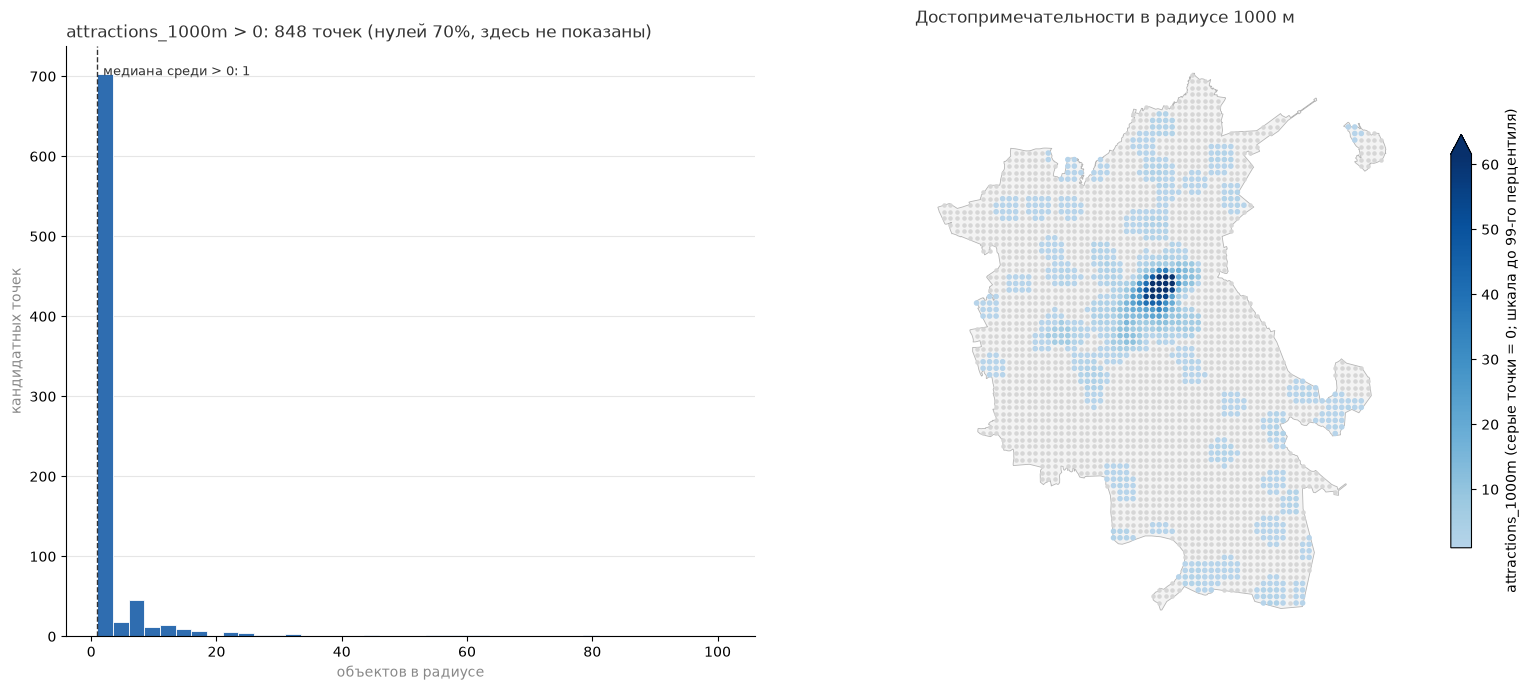

сохранено: data\processed\features\attractions_1000m.csv (2822, 2)


In [29]:
FEATURES["attractions_1000m"] = count_within(attractions, 1000, "attractions_1000m", as_points=False)
describe_feature(FEATURES["attractions_1000m"], "attractions_1000m")
plot_feature(FEATURES["attractions_1000m"], "attractions_1000m", "Достопримечательности в радиусе 1000 м")
save_feature(FEATURES["attractions_1000m"], "attractions_1000m")

## 11. Итог: все признаки в одном файле

`data/processed/features/osm_commercial_features.csv`: `candidate_id`, `x`, `y` и 8 признаков. Отдельные файлы по признакам лежат рядом. Проверяем: 2822 строки, уникальные id, ни одного пропуска.

In [30]:
FEATURE_ORDER = ["shops_500m", "malls_1000m", "restaurants_500m", "metro_dist",
                 "transit_stops_500m", "parking_500m", "major_roads_distance", "attractions_1000m"]

osm_features = candidates[["candidate_id", "x", "y"]].copy()
for name in FEATURE_ORDER:
    osm_features = osm_features.merge(FEATURES[name], on="candidate_id", how="left", validate="one_to_one")

assert osm_features.shape == (N_CANDIDATES, 3 + len(FEATURE_ORDER))
assert osm_features["candidate_id"].is_unique
assert osm_features.isna().sum().sum() == 0

combined_path = FEATURES_DIR / "osm_commercial_features.csv"
osm_features.to_csv(combined_path, index=False)
print("сохранено:", combined_path.relative_to(PROJECT_ROOT), osm_features.shape)
osm_features[FEATURE_ORDER].describe().T.round(1)

сохранено: data\processed\features\osm_commercial_features.csv (2822, 11)


,count,mean,std,min,25%,50%,75%,max
shops_500m,2822.0,4.1,12.0,0.0,0.0,0.0,2.0,147.0
malls_1000m,2822.0,0.3,1.1,0.0,0.0,0.0,0.0,16.0
restaurants_500m,2822.0,0.6,2.3,0.0,0.0,0.0,0.0,33.0
metro_dist,2822.0,9027.6,5720.3,87.9,4532.2,8106.3,12536.9,25253.5
transit_stops_500m,2822.0,2.2,3.5,0.0,0.0,0.0,4.0,25.0
parking_500m,2822.0,2.8,7.3,0.0,0.0,0.0,2.0,84.0
major_roads_distance,2822.0,2278.8,2861.8,0.3,256.0,1023.2,3309.1,13975.8
attractions_1000m,2822.0,1.3,6.1,0.0,0.0,0.0,1.0,101.0


In [31]:
# пропуски и доля нулей по всем признакам
pd.DataFrame({
    "пропусков": osm_features[FEATURE_ORDER].isna().sum(),
    "доля нулей": (osm_features[FEATURE_ORDER] == 0).mean().round(3),
})

,пропусков,доля нулей
shops_500m,0,0.640
malls_1000m,0,0.843
restaurants_500m,0,0.842
metro_dist,0,0.000
transit_stops_500m,0,0.557
parking_500m,0,0.608
major_roads_distance,0,0.000
attractions_1000m,0,0.700


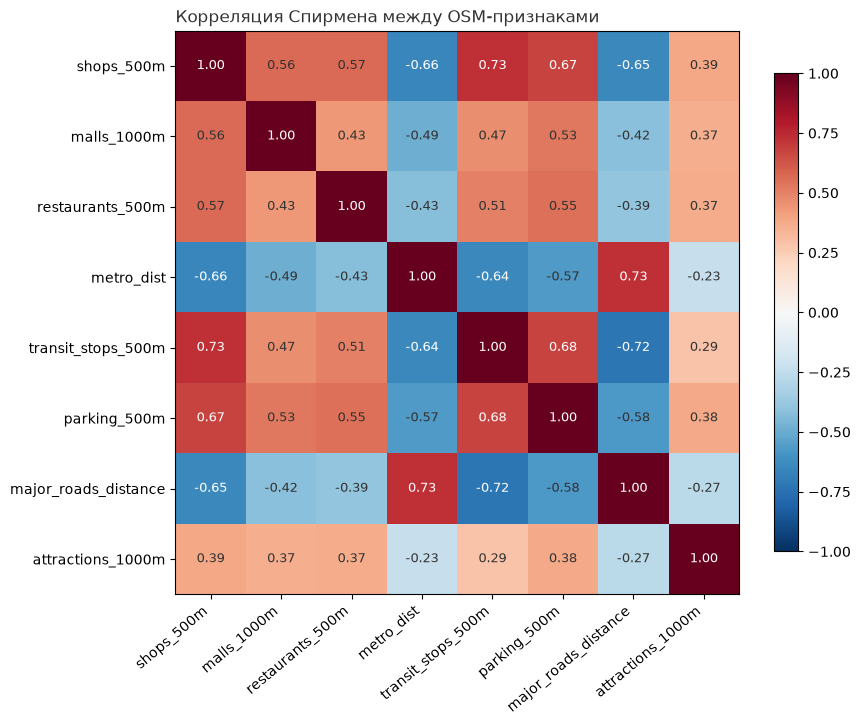

In [32]:
# корреляции Спирмена: какие признаки дублируют друг друга
corr = osm_features[FEATURE_ORDER].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURE_ORDER)), FEATURE_ORDER, rotation=40, ha="right")
ax.set_yticks(range(len(FEATURE_ORDER)), FEATURE_ORDER)
for i in range(len(FEATURE_ORDER)):
    for j in range(len(FEATURE_ORDER)):
        value = corr.iat[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(value) > 0.6 else INK)
ax.set_title("Корреляция Спирмена между OSM-признаками", loc="left", color=INK)
fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

### Как объединять с признаками из других ноутбуков

`candidate_id` — номер строки в `candidate_locations.gpkg`. Перед объединением проверяем, что координаты совпали:

In [33]:
osm_features = pd.read_csv(FEATURES_DIR / "osm_commercial_features.csv")
base = candidates[["candidate_id", "geometry"]]  # у вас: gpd.read_file(...candidate_locations.gpkg).reset_index(drop=True) + candidate_id = range(len)
merged = base.merge(osm_features, on="candidate_id", how="left", validate="one_to_one")
assert np.allclose(merged.geometry.x, merged["x"], atol=0.01) and np.allclose(merged.geometry.y, merged["y"], atol=0.01)
print("координаты совпадают, строк:", len(merged))

координаты совпадают, строк: 2822


### Выводы

**Качество данных.** Все 8 признаков посчитаны для 2822 точек, пропусков нет, `candidate_id` уникальны, координаты сходятся с сеткой из 02. В исходных слоях не нашлось пустых геометрий и дублей OSM-id; 79 невалидных геометрий во всей выгрузке приходятся на слои, которые сюда не вошли. Основная чистка — смысловые дубли:
- 17 магазинов, 14 ресторанов, 3 ТРЦ (части «Мерей» и «Алтын Орда»), 10 парковок, 10 достопримечательностей;
- у остановок 83 двойных платформы и 860 `stop_position`, которые дублируют платформу.

**Распределения.**
- Счётные признаки сильно зажаты к нулю: нулей 56% (`transit_stops_500m`) … 84% (`malls_1000m`, `restaurants_500m`), хвосты длинные (до 147 магазинов и 101 достопримечательности). Для линейных моделей стоит взять `log1p`; деревьям это не нужно.
- `metro_dist`: одна линия метро, медиана 8,1 км. Ближе 1 км к метро всего 105 точек из 2822. Вероятно, полезнее бинарный признак «метро ≤ 1 км» или `log1p(metro_dist)`.
- `major_roads_distance`: медиана ~1 км, у 1042 точек крупная дорога ближе 500 м. Самые большие значения — горная южная часть города.

**Связь признаков.**
- `transit_stops_500m` почти совпадает с `bus_stops_500m` из 02 (Spearman 0,995): 99% остановок автобусные/троллейбусные, а 11 станций метро и 8 ж/д станций почти ничего не меняют. **В модель стоит брать только один из них.**
- Остальные корреляции не выше 0,73: магазины ↔ остановки, `metro_dist` ↔ `major_roads_distance`. Все они отражают «центральность» района, но не дублируют друг друга. Это стоит учесть при отборе признаков.

**Что можно поменять одной строкой.** Состав магазинов (`SHOP_EXCLUDE`), парковок (`PARKING_EXCLUDE_*`), достопримечательностей (`ATTRACTION_*`), классы крупных дорог (`MAJOR_HIGHWAYS`), запас зоны поиска (`STUDY_BUFFER_M`).